# DATA-445: In-Class Assignment 17

**1.** Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- `ID:` customer ID
- `Visit_Time:` The number of visits to the company's website in a given month.
- `Average_Expense:` The average amount of money that the customer has spend.
- `Sex:` gender of the customer (0: female, 1: male).
- `Age:` age of the customer.

**In Python**, answer the following:

**(a)** (3 points) Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [7]:
import pandas as pd

customers = pd.read_csv('customers.csv')
customers.head()

,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


**(b)** (3 points) Using the appropriate Python commands, remove the `ID` variable.

In [8]:
customers = customers.drop(columns=['ID'])
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,3,5.7,0,10
1,5,14.5,0,27
2,16,33.5,0,32
3,5,15.9,0,30
4,16,24.9,0,23


**(c)** (5 points) Using the appropriate standardization formula, put all the variables on the same scale. *Hint:* Notice that `Sex` is a 0-1 variable.

In [9]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
customers[['Visit_Time', 'Average_Expense', 'Age']] = scaler.fit_transform(customers[['Visit_Time', 'Average_Expense', 'Age']])
customers.head()


,Visit_Time,Average_Expense,Sex,Age
0,0.117647,0.041096,0,0.051282
1,0.235294,0.342466,0,0.487179
2,0.882353,0.993151,0,0.615385
3,0.235294,0.390411,0,0.564103
4,0.882353,0.698630,0,0.384615


**(d)** (8 points) Using the silhouette score, estimate the number of cluster for this dataset. Consider 2 to 20 clusters. Make sure to use `n_init=20`.

c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\15154\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Window

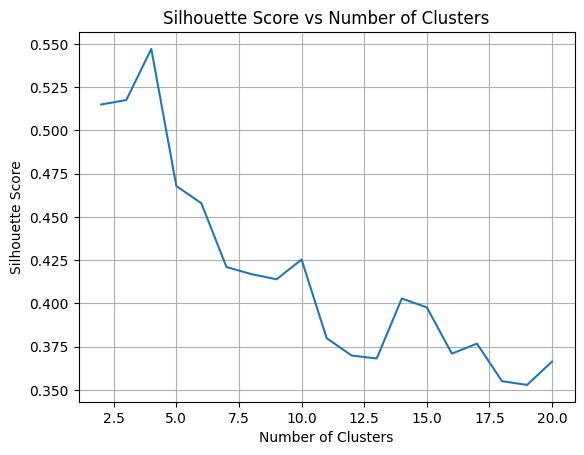

0.3664734290250274

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []


for i in range(2, 21):
    kmeans = KMeans(n_clusters=i, n_init=20, random_state=42)
    kmeans.fit(customers)
    score = silhouette_score(customers, kmeans.labels_)
    silhouette_scores.append(score)

import matplotlib.pyplot as plt
plt.plot(range(2, 21), silhouette_scores)
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.grid(True)
plt.show()

score

From above, 4 clusters maximizes the silhouette score.

**(e)** (6 points) Using the `cmeans` function from the `skfuzzy.cluster` library, cluster the customers into the number of clusters estimated from part (d).

In [12]:
#%pip install scikit-fuzzy
# %pip install fuzzy-c-means
from skfuzzy.cluster import cmeans
n_clusters = 4
data = customers.values.T

cntr, u, u0, d, jm, p, fpc = cmeans(data, n_clusters, m=2, error=0.005, maxiter=1000)

**(f)** (10 points) Change the likelihoods to cluster labels using 70% as threshold. Describe each of the clusters from part (d).

In [14]:
import numpy as np

customers["Cluster"] = np.nan

w = u

customers["Cluster"] = np.where(w[0] > 0.7, 0, customers["Cluster"])
customers["Cluster"] = np.where(w[1] > 0.7, 1, customers["Cluster"])
customers["Cluster"] = np.where(w[2] > 0.7, 2, customers["Cluster"])
customers["Cluster"] = np.where(w[3] > 0.7, 3, customers["Cluster"])

customers["Cluster"].value_counts(normalize=True)


Cluster
2.0    0.431373
0.0    0.235294
1.0    0.176471
3.0    0.156863
Name: proportion, dtype: float64